In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import anndata as ad
#import squidpy as sq
 
import pickle




# Load final version

In [3]:
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sc.settings.figdir = "fig1"
sc.settings.set_figure_params(dpi_save=300, facecolor="white", frameon=False, figsize=(8,8))


In [4]:
PATH = '/nfs/team298/ls34/adult_skin/final_adatas/adata_combined_inc_relapse_webportal.h5ad'

adata_5k=sc.read_h5ad(PATH)
adata_5k=adata_5k[adata_5k.obs["tech"]=='xenium'].copy()
import gc
gc.collect()
def remove_markers(LIST):
    try: 
        LIST = {key: [gene for gene in genes if gene in adata_5k.var_names] 
                           for key, genes in LIST.items()}
    except: 
        LIST =[gene for gene in LIST if gene in adata_5k.var_names]
    return LIST





# Recode T cells

In [5]:
RENAME = {'T': 'T',
 'Treg': 'T_other',
 'TRM_IL13+': 'TRM_IL13+',
 'Th': 'T_other',
 'T_γδ': 'T_other',
 'Tnaive': 'T_other',
 'Tc': 'T_other',
 'Treg_LRRC32+': 'T_other',
 'T_Prolif': 'T_other',
 'Th_PPARGhi': 'T_other',
 'TRM_IL17+': 'TRM_IL17+',
         'Tc1':   'T_other',
'Tc0': 'T_other',
'Tc3_IFNGhi': 'T_other',
'Tc2': 'T_other',
'Treg/Tnaive_prolif': 'T_other',
'TR1': 'T_other',
'Th/TRM prolif':  'T_other',
#'TransitionalDC'
'Tc_Prolif': 'T_other',
          "TRM_prolif":  "TRM_prolif",
         
         }
adata_5k.obs["tcells2"] =  adata_5k.obs["lvl5_annotation"].map(RENAME).fillna("Other")


In [6]:
[x for x in adata_5k.obs["lvl5_annotation"].unique() if x.startswith("T") and x not in RENAME.keys()]

['TransitionalDC', 'Tnaive_CD8']

In [6]:
i=0
for x in [x for x in adata_5k.obs["lvl5_annotation"].unique() if x.startswith("T")]:
    if x not in RENAME.keys():
        print(x)

TransitionalDC
Tnaive_CD8


In [7]:
file_path = "/nfs/team298/ls34/dicts/color_for_adult_skin3.pkl"

with open(file_path, "rb") as fh:
    colors = pickle.load(fh)


colors = colors | {        'T_other':'#F4D1A1',
                   "T": '#F4D1A1', #'#8C6A3B',
                   "TRM_CD4+": "#39FF14"
                  
                  }



# Choose samples with matching Akoya data (for 3D samples)

In [8]:
SAMPLE = '3D_Lesional_baseline'
adata_5k_i = adata_5k[adata_5k.obs["Site_status"]==SAMPLE].copy()


In [14]:
# [x for x in adata_5k.obs.info_id6.unique() if "BK22" in x and "D1" in x]

['3D_BK22_Lesional_baseline-D1']

3D_BK22_Lesional_baseline-D1


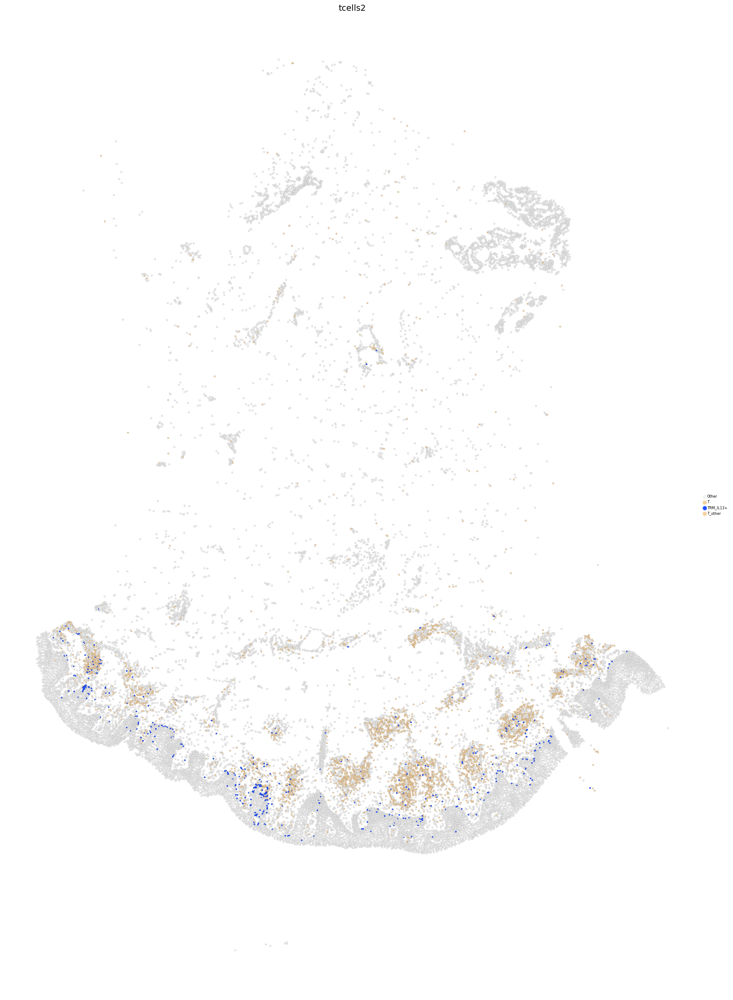

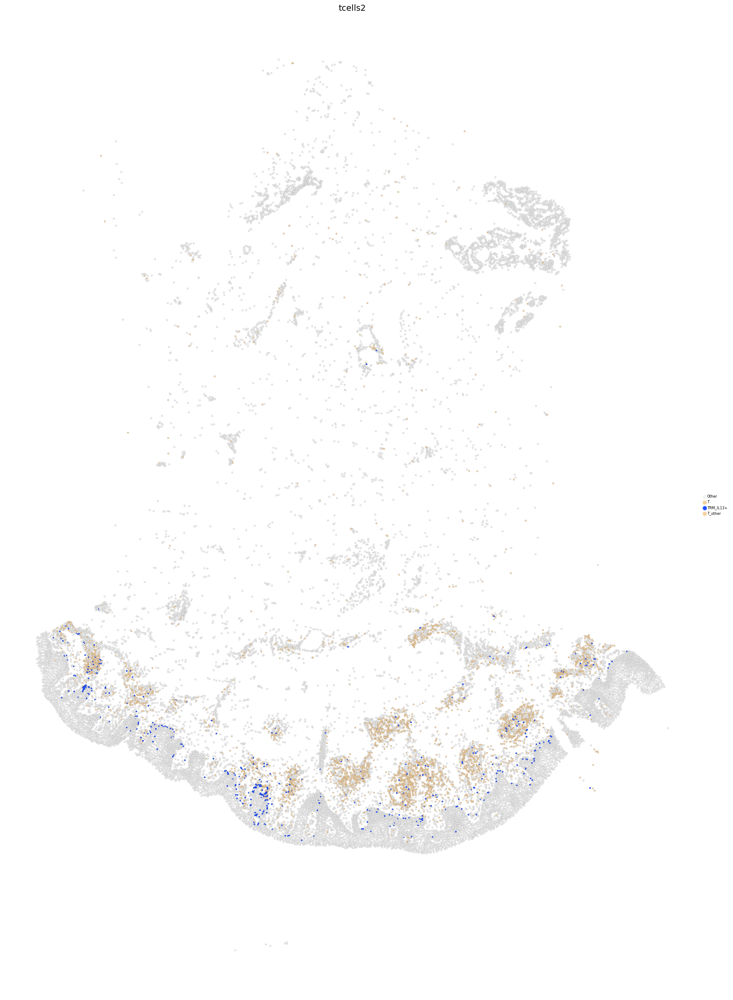

In [15]:
sc.settings.set_figure_params(dpi=50,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

for SAMPLE in [#"BK22-SKI-27-FO-1-S57-D2",
    "3D_BK22_Lesional_baseline-D1"]:
    print(SAMPLE)
    adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] == SAMPLE]

    adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
    adata_i.uns['tcells2_colors'] = [
        colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
    ]


    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.1,
        legend_fontsize=6,
        #show=True
       save=f"1g_trm_il13_{SAMPLE}+_smaller.pdf"

    )
    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.1,
        legend_fontsize=6,
        #show=True
       save=f"1g_trm_il13_{SAMPLE}+_smallest.pdf"

    )
 

Processing 7 samples with > 20 TRM_IL13+ cells and >500 total cells


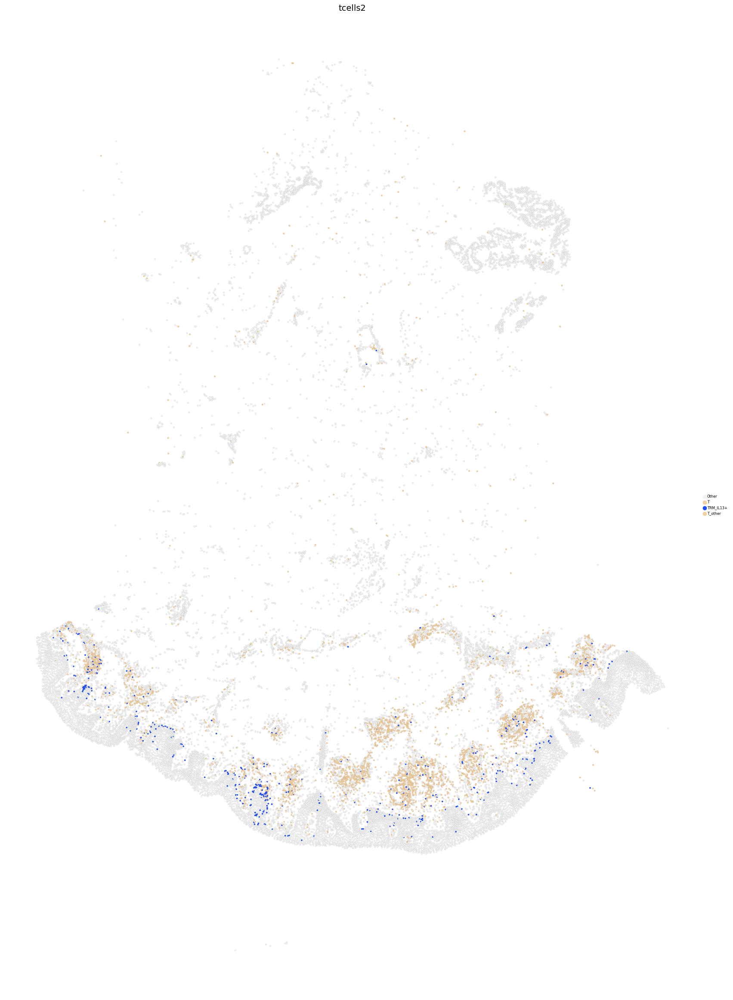

In [17]:
MIN_CELLS = 20

trm_counts = adata_5k_i.obs.loc[
    adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
    "info_id6"
].value_counts()
MIN_CELLS = 20

trm_counts = adata_5k_i.obs.loc[
    adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
    "info_id6"
].value_counts()

samples_to_keep = trm_counts[trm_counts > MIN_CELLS].index


total_counts = adata_5k_i.obs["info_id6"].value_counts()
samples_to_keep = samples_to_keep.intersection(total_counts[total_counts > 500].index)

print(f"Processing {len(samples_to_keep)} samples with > {MIN_CELLS} TRM_IL13+ cells and >500 total cells")

sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(30,30))

adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] == '3D_BK22_Lesional_baseline-D1']
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]
# print(adata_i.shape)
# sc.pl.spatial(
#     adata_i,
#     #library_id="spatial",
#     #shape=None,
#     color="tcells",
#     spot_size=10,
#     vmax=1,
#     #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
#     edgecolor="black",
#     linewidth=0.05,
#     legend_fontsize=6,
#     #show=True
#     save="fig1_trm_il13.pdf"

# )

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.05,
    legend_fontsize=6,
    #show=True
    save="fig1_trm_il13_2.pdf"

)
 

In [18]:
MIN_CELLS = 20
sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

# trm_counts = adata_5k_i.obs.loc[
#     adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
#     "info_id6"
# ].value_counts()
# MIN_CELLS = 20

# trm_counts = adata_5k_i.obs.loc[
#     adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
#     "info_id6"
# ].value_counts()

# samples_to_keep = trm_counts[trm_counts > MIN_CELLS].index


# total_counts = adata_5k_i.obs["info_id2"].value_counts()
# samples_to_keep = samples_to_keep.intersection(total_counts[total_counts > 500].index)

# print(f"Processing {len(samples_to_keep)} samples with > {MIN_CELLS} TRM_IL13+ cells and >500 total cells")

# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(30,30))

adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] =='3D_BK22_Lesional_baseline-D1']
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]
# print(adata_i.shape)
# sc.pl.spatial(
#     adata_i,
#     #library_id="spatial",
#     #shape=None,
#     color="tcells",
#     spot_size=10,
#     vmax=1,
#     #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
#     edgecolor="black",
#     linewidth=0.05,
#     legend_fontsize=6,
#     #show=True
#     save="fig1_trm_il13.pdf"

# )

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.2,
    legend_fontsize=6,
    #show=True
    save="fig1_NEW_TRM_BASELINELESIONAL.pdf"

)
 

In [ ]:

# sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))


    
# #     adata_i.obs["tcells3"] = pd.Categorical(
# #         adata_i.obs["tcells3"],
# #         categories=desired_order,
# #         ordered=True
# #     )

    
# #     adata_i.obs["tcells3"] = adata_i.obs["tcells3"].astype("category")
# #     adata_i.uns['tcells3_colors'] = [
# #         colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells3'].cat.categories
# #     ]



# sc.pl.spatial(
#     adata_i,
#     #library_id="spatial",
#     #shape=None,
#     color="tcells2",
#     spot_size=10,
#     vmax=1,
#     #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
#     edgecolor="black",
#     linewidth=0.2,
#     legend_fontsize=6,
#     #show=True
#  save=f"NEW_TRMWEEK12_{SAMPLE}+_smaller.pdf"

# )


In [ ]:
STOP

In [ ]:

sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

SAMPLE = "3D_BK25_week12-C1"
adata_i = adata_5k[adata_5k.obs["info_id6"] ==SAMPLE]
 
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.2,
    legend_fontsize=6,
    #show=True
 save=f"NEW_TRMWEEK12_{SAMPLE}+_smaller.pdf"

)


In [ ]:
adata_5k.obs.Site_status.value_counts()

In [10]:
adata_5k[adata_5k.obs["lvl5_annotation"]=="TRM_IL13+"].obs.sample_id.value_counts()#.copy()


sample_id
3D_BK25_week12-D2                                                                       1281
BK25_Week 12                                                                             865
BK39_Week 12                                                                             809
3D_BK25_week12-C2                                                                        706
3D_BK25_week12-C1                                                                        635
                                                                                        ... 
output-XETG00272__0081038__BK73-SKI-27-FO-1-s2__20260413__125221                           3
output-XETG00272__0080896__BK70-SKI-0-FO-1-s5__20260413__125221                            1
output-XETG00272__0080896__BK70-SKI-22-FO-1-s5_BK72-SKI-26-FO-1-s5__20260413__125221       1
output-XETG00272__0080896__BK70-SKI-28-FO-1-s5__20260413__125220                           1
output-XETG00272__0080896__BK70-SKI-27-FO-1-s5__20260413__12

In [ ]:

sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

SAMPLE = "3D_BK25_week12-C1"
adata_i = adata_5k[adata_5k.obs["info_id6"] ==SAMPLE]
 
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.2,
    legend_fontsize=6,
    #show=True
 save=f"NEW_TRMWEEK12_{SAMPLE}+_smaller.pdf"

)


In [ ]:
S

# include TRM 4+

In [ ]:
import pickle
with open("/nfs/team298/ls34/anno13.pkl", "rb") as f:
    md = pickle.load(f)

# md now contains the dictionary
print(type(md))
print(list(md.keys())[:10])  # peek at first 10 keys

In [ ]:
adata_5k.obs["Annotation13"]=adata_5k.obs.index.map(md)

In [ ]:
adata_5k.obs["Annotation13"].isna().sum()

In [ ]:
{x:x for x in adata_5k.obs["Annotation13"].unique() if x not in RENAME.keys()}

In [ ]:
RENAME = {'T': 'T_other',
 'Treg': 'T_other',
 'TRM_IL13+': 'TRM_IL13+',
 'Th': 'T_other',
 'T_γδ': 'T_other',
 'Tnaive': 'T_other',
 'Tc': 'T_other',
 'Treg_LRRC32+': 'T_other',
 'T_Prolif': 'T_other',
 'Th_PPARGhi': 'T_other',
 'TRM_IL17+': 'TRM_IL17+',
         'Tc1':   'T_other',
'Tc0': 'T_other',
'Tc3_IFNGhi': 'T_other',
'Tc2': 'T_other',
'Treg/Tnaive_prolif': 'T_other',
'TR1': 'T_other',
'Th/TRM prolif':  'T_other',
#'TransitionalDC'
'Tc_Prolif': 'T_other',
          "TRM_prolif":  "TRM_prolif",
          
          
          
           'T_lowcounts': 'T_other',
 'Th_KLRG1+': 'T_other',
 'T_CD8+_lowcounts': 'T_other',
 'Th17_ZBTB16+': 'T_other',
 'Tγδ': 'T_other',
 'NK': 'T_other',
 'ILC3': 'T_other',
 'ILC1': 'T_other',
 'Tc2_GZMH+': 'T_other',
 'Tc3_IFNGhi_CCL3+': 'T_other',
 'CD8+_Prolif': 'T_other',
 'Th2': 'T_other',
 'TRM_CD4+': 'TRM_CD4+',
 'CD4_Tex_GZMK+IL10+PDCD1+': 'T_other',
 'ILC3_CCL1+PTGDS+': 'T_other',
 'ILC_Prolif': 'T_other',
 'ILC2': 'T_other',
 'Th1/Tc_IFNG+': 'T_other',
 'Tfh-like': 'T_other',
 'ILC1_NCR2+P2RX7+': 'T_other',
 'Tc1_BACH2+': 'T_other',
 'Tc2_GZMH+TOX+': 'T_other',
 'ILC3_Early': 'T_other',
 'TRM_IL17+??': 'TRM_IL17+',
 'ILC_Stress': 'T_other',
 'CD4+_Prolif': 'T_other',
 'TRM_IL13+/KC': 'TRM_IL13+',
 'TRM_ITGA1+PDCD1+': 'T_other'
          
          
         
         }
adata_5k.obs["tcells2"] =  adata_5k.obs["Annotation13"].map(RENAME).fillna("Other")
#[x for x in adata_5k.obs["Annotation13"].unique() if x.startswith("T") and x not in RENAME.keys()]

In [ ]:
SAMPLE = '3D_Lesional_baseline'
adata_5k_i = adata_5k[adata_5k.obs["Site_status"]==SAMPLE].copy()


In [ ]:
sc.settings.set_figure_params(dpi=50,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

for SAMPLE in [#"BK22-SKI-27-FO-1-S57-D2",
    "BK22-SKI-27-FO-1-S34-D1"]:
    print(SAMPLE)
    adata_i = adata_5k_i[adata_5k_i.obs["info_id2"] == SAMPLE]

    adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
    adata_i.uns['tcells2_colors'] = [
        colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
    ]


    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.1,
        legend_fontsize=6,
        #show=True
       #save=f"1g_trm_il13_{SAMPLE}+_smaller.pdf"

    )
    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.1,
        legend_fontsize=6,
        #show=True
       save=f"1g_trm_il13_{SAMPLE}+_smallest_new.pdf"

    )
 

In [ ]:
MIN_CELLS = 20

trm_counts = adata_5k_i.obs.loc[
    adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
    "info_id6"
].value_counts()
MIN_CELLS = 20

trm_counts = adata_5k_i.obs.loc[
    adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
    "info_id6"
].value_counts()

samples_to_keep = trm_counts[trm_counts > MIN_CELLS].index


total_counts = adata_5k_i.obs["info_id2"].value_counts()
samples_to_keep = samples_to_keep.intersection(total_counts[total_counts > 500].index)

print(f"Processing {len(samples_to_keep)} samples with > {MIN_CELLS} TRM_IL13+ cells and >500 total cells")

sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(30,30))

adata_i = adata_5k_i[adata_5k_i.obs["info_id2"] == 'BK22-SKI-27-FO-1-S17-A1']
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]
# print(adata_i.shape)
# sc.pl.spatial(
#     adata_i,
#     #library_id="spatial",
#     #shape=None,
#     color="tcells",
#     spot_size=10,
#     vmax=1,
#     #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
#     edgecolor="black",
#     linewidth=0.05,
#     legend_fontsize=6,
#     #show=True
#     save="fig1_trm_il13.pdf"

# )

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.05,
    legend_fontsize=6,
    #show=True
    save="fig1_trm_il13_2new.pdf"

)
 

In [ ]:
MIN_CELLS = 20
sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

# trm_counts = adata_5k_i.obs.loc[
#     adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
#     "info_id6"
# ].value_counts()
# MIN_CELLS = 20

# trm_counts = adata_5k_i.obs.loc[
#     adata_5k_i.obs["lvl5_annotation"] == "TRM_IL13+",
#     "info_id6"
# ].value_counts()

# samples_to_keep = trm_counts[trm_counts > MIN_CELLS].index


# total_counts = adata_5k_i.obs["info_id2"].value_counts()
# samples_to_keep = samples_to_keep.intersection(total_counts[total_counts > 500].index)

# print(f"Processing {len(samples_to_keep)} samples with > {MIN_CELLS} TRM_IL13+ cells and >500 total cells")

# sc.settings.set_figure_params(dpi=50, facecolor="white", frameon=False, figsize=(30,30))

adata_i = adata_5k_i[adata_5k_i.obs["info_id6"] =='3D_BK22_Lesional_baseline-D1']
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]
# print(adata_i.shape)
# sc.pl.spatial(
#     adata_i,
#     #library_id="spatial",
#     #shape=None,
#     color="tcells",
#     spot_size=10,
#     vmax=1,
#     #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
#     edgecolor="black",
#     linewidth=0.05,
#     legend_fontsize=6,
#     #show=True
#     save="fig1_trm_il13.pdf"

# )

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.2,
    legend_fontsize=6,
    #show=True
    save="fig1_NEW_TRM_BASELINELESIONALnew.pdf"

)
 

In [ ]:

sc.settings.set_figure_params(dpi=300,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

SAMPLE = "3D_BK25_week12-C1"
adata_i = adata_5k[adata_5k.obs["info_id6"] ==SAMPLE]
 
STATUS = adata_i.obs["Site_status"].unique()[0]

# # Setup categorical colors only once per sample
# adata_i.obs["tcells"] = adata_i.obs["tcells"].astype("category")
# adata_i.uns['tcells_colors'] = [
#     colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells'].cat.categories
# ]

adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
adata_i.uns['tcells2_colors'] = [
    colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
]

sc.pl.spatial(
    adata_i,
    #library_id="spatial",
    #shape=None,
    color="tcells2",
    spot_size=10,
    vmax=1,
    #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
    edgecolor="black",
    linewidth=0.2,
    legend_fontsize=6,
    #show=True
 save=f"NEW_TRMWEEK12_{SAMPLE}+_smallerNEW.pdf"

)


# extra (not in mpaper for space but quite nice visualisation of MigDC-heavy Tzone)

In [ ]:
RENAME = {'T': 'T',
 'Treg': 'Treg',
 'TRM_IL13+': 'TRM_IL13+',
 'Th': 'T_other',
 'T_γδ': 'T_other',
 'Tnaive': 'T_other',
 'Tc': 'T_other',
 'Treg_LRRC32+': 'Treg_LRRC32+',
 'T_Prolif': 'T_other',
 'Th_PPARGhi': 'T_other',
 'TRM_IL17+': 'TRM_IL17+',
         'Tc1':   'T_other',
'Tc0': 'T_other',
'Tc3_IFNGhi': 'T_other',
'Tc2': 'T_other',
'Treg/Tnaive_prolif': 'T_other',
'TR1': 'T_other',
'Th/TRM prolif':  'T_other',
#'TransitionalDC'
'Tc_Prolif': 'T_other',
          "TRM_prolif":  "TRM_prolif",
          'ILC3': 'ILC3',
 'ILC2': 'ILC2',
 'ILC3_CCL1+PTGDS+': 'ILC3_CCL1+PTGDS+',
 'ILC1': 'ILC1',
 'ILC1_NCR2+P2RX7+': 'ILC1_NCR2+P2RX7+',
 'ILC_Prolif': 'ILC_Prolif',
          'MigDC (cDC2)': 'MigDC (cDC2)',
          
         
         }
adata_5k.obs["tcells2"] =  adata_5k.obs["lvl5_annotation"].map(RENAME).fillna("Other")


In [ ]:

sc.settings.set_figure_params(dpi=50,dpi_save=300 , facecolor="white", frameon=False, figsize=(30,30))

for SAMPLE in ["BK25-SKI-27-FO-5"]:
    print(SAMPLE)
    adata_i = adata_5k[adata_5k.obs["Sample ID"] == SAMPLE]
    #adata_i=adata_i[adata_i.obs["niche19"].str.startswith("Epi")]

    adata_i.obs["tcells2"] = adata_i.obs["tcells2"].astype("category")
    adata_i.uns['tcells2_colors'] = [
        colors.get(cat, '#D3D3D3') for cat in adata_i.obs['tcells2'].cat.categories
    ]

    
    

    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.3,
        legend_fontsize=6,
        #show=True
      save=f"1g_trm_il13_{SAMPLE}+WEEK12_smaller.pdf"

    )
    sc.pl.spatial(
        adata_i,
        #library_id="spatial",
        #shape=None,
        color="tcells2",
        spot_size=10,
        vmax=1,
        #title=f"{STATUS}_{DONOR_ID}\n{adata_i.shape[0]}",
        edgecolor="black",
        linewidth=0.2,
        legend_fontsize=6,
        #show=True
       save=f"1g_trm_il13_{SAMPLE}+WEEK12_smallest.pdf"
#
    )
 